# **MÓDULO 39 - Exercicio - Aplicando SVM**

Nessa atividade vocês usarão uma base já connhecida, a base de propensão a compra de carros. A mesma que também usamos na tarefa de XGboost!


In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import (
    train_test_split, 
    RandomizedSearchCV,
    StratifiedKFold, 
    cross_val_score
)
from sklearn.metrics import (
    classification_report, 
    confusion_matrix, 
    ConfusionMatrixDisplay, 
    roc_auc_score, 
    roc_curve
)
from sklearn.inspection import permutation_importance

# 1. Carrega a base de dados, verifique os tipos de dados, dados faltantes e drop a coluna ID.


In [2]:
df = pd.read_csv('CARRO_CLIENTES.csv')

In [3]:
df.isnull().sum()

User ID         0
Gender          0
Age             0
AnnualSalary    0
Purchased       0
dtype: int64

In [4]:
df.dtypes

User ID         int64
Gender            str
Age             int64
AnnualSalary    int64
Purchased       int64
dtype: object

In [5]:
df = df.drop(columns=['User ID'])

In [6]:
df.head()

,Gender,Age,AnnualSalary,Purchased
0,Male,35,20000,0
1,Male,40,43500,0
2,Male,49,74000,0
3,Male,40,107500,1
4,Male,25,79000,0


# 2. Aplique o Label Encoder para a coluna Gender e exclua a coluna categórica.

In [7]:
encoder = LabelEncoder()

In [8]:
scaler = StandardScaler()

In [9]:
df['Gender_encoded'] = encoder.fit_transform(df['Gender'])

In [10]:
df['Age_scaled'] = scaler.fit_transform(df[['Age']])
df['AnnualSalary_scaled'] = scaler.fit_transform(df[['AnnualSalary']])

In [11]:
df = df.drop(columns=['Gender', 'Age', 'AnnualSalary'])

In [12]:
df.head()

,Purchased,Gender_encoded,Age_scaled,AnnualSalary_scaled
0,0,1,-0.477120,-1.528498
1,0,1,-0.009905,-0.846767
2,0,1,0.831082,0.038032
3,1,1,-0.009905,1.009861
4,0,1,-1.411549,0.183081


Optei por padronizar as variáveis numéricas `Age` e `AnnualSalary` utilizando o `StandardScaler`, pois elas apresentam escalas muito diferentes. O modelo `SVM` geralmente apresenta melhores resultados quando as variáveis numéricas são **padronizadas**. Isso acontece porque o algoritmo é sensível à escala dos dados, especialmente quando utiliza os kernels `linear`, `poly` e `rbf`.

Além disso, antes da padronização, o treinamento estava demorando excessivamente, permanecendo cerca de 10 minutos em execução sem apresentar resultados. Após aplicar a padronização, o modelo passou a executar mais rapidamente, permitindo realizar os testes com os diferentes hiperparâmetros.

# 3. Faça a matriz de correlação e analise as váriaveis que parecem ter maior correlação com a váriavel target.

In [13]:
cmatriz = df.select_dtypes(include='number').corr()
cmatriz

,Purchased,Gender_encoded,Age_scaled,AnnualSalary_scaled
Purchased,1.000000,-0.047211,0.616036,0.364974
Gender_encoded,-0.047211,1.000000,-0.084760,-0.063301
Age_scaled,0.616036,-0.084760,1.000000,0.166042
AnnualSalary_scaled,0.364974,-0.063301,0.166042,1.000000


As variáveis com maior correlação com a target (`Purchased`) são: `Age` (0.61) e `AnnualSalary` (0.36).

# 4. Faça a separação da base em X e Y e em seguida nas bases de treino e teste.

In [14]:
X = df.drop(columns=['Purchased'])
Y = df['Purchased']

In [15]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

# 5. Treino o modelo SVM com sua base de treino e teste e traga a avaliação

### **Modelo 1: kernel = 'linear'**

In [16]:
model = SVC(kernel='linear')

In [17]:
param_grid_linear ={
    "C": [0.1, 1, 10]
}

[LINK DA DOCUMENTAÇÃO](https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html)

| **Parâmetro** | **Controla** | **Aumentar o valor tende a...** |
|---|---|---|
| `C` | Penalização dos erros de classificação | Reduzir a regularização e permitir uma fronteira mais ajustada aos dados de treinamento |
| `degree` | Grau do polinômio | Aumentar a complexidade da fronteira de decisão |
| `gamma` | Influência das características na função do kernel | Aumentar a influência dos valores das características na função polinomial, podendo produzir fronteiras mais complexas |
| `coef0` | Influência do termo independente na função polinomial | Aumentar a contribuição dos termos de menor grau em relação aos de maior grau |

In [18]:
cross_validation = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [19]:
random_search = RandomizedSearchCV(
    model, 
    param_distributions=param_grid_linear,
    n_iter=3,
    cv=cross_validation,
    scoring='accuracy',
    n_jobs=-1,
    random_state=42
)

In [20]:
random_search.fit(X_train, Y_train)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",SVC(kernel='linear')
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'C': [0.1, 1, ...]}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",3
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"ve

In [21]:
best_param = random_search.best_params_
print(f'Melhores Parâmetros: {best_param}')

Melhores Parâmetros: {'C': 10}


In [22]:
best_model = random_search.best_estimator_
best_model.fit(X_train, Y_train)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",10
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'linear'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide `.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide `.",False
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


### Treino:

In [23]:
Y_pred1 = best_model.predict(X_train)

report = classification_report(Y_train, Y_pred1)
print(f'Relatório de Classificação: \n{report}')

Relatório de Classificação: 
              precision    recall  f1-score   support

           0       0.83      0.90      0.86       486
           1       0.82      0.72      0.77       314

    accuracy                           0.83       800
   macro avg       0.83      0.81      0.82       800
weighted avg       0.83      0.83      0.83       800



O modelo `SVC` com kernel `linear` apresentou `accuracy` de 83% no conjunto de treinamento. Para a classe 0, obteve `precision` de 83% e `recall` de 90%, enquanto, para a classe 1, alcançou `precision` de 82% e `recall` de 72%. Esses resultados indicam que o modelo apresenta mais dificuldade para identificar os clientes que compraram o carro (classe 1).

### Validação cruzada:

In [24]:
scores = cross_val_score(
    best_model,
    X_train,
    Y_train,
    cv=cross_validation,
    scoring='accuracy',
    n_jobs=-1,
)

In [25]:
print(f'Scores cross validation: {scores}')
print(f'Acurácia média: {np.mean(scores):.2f}')
print(f'Desvio padrão: {np.std(scores):.2f}')

Scores cross validation: [0.85    0.7875  0.83125 0.83125 0.83125]
Acurácia média: 0.83
Desvio padrão: 0.02


A **validação cruzada**, apresentou uma accuracy média de 83% e um desvio padrão (`std`) de 2 pontos percentuais. Os resultados demonstram que o modelo mantém um desempenho relativamente estável entre as diferentes partições dos dados.

### Teste:

In [26]:
Y_pred2 = best_model.predict(X_test)

report = classification_report(Y_test, Y_pred2)
print(f'Relatório de Classificação: \n{report}')

Relatório de Classificação: 
              precision    recall  f1-score   support

           0       0.77      0.94      0.84       112
           1       0.89      0.64      0.74        88

    accuracy                           0.81       200
   macro avg       0.83      0.79      0.79       200
weighted avg       0.82      0.81      0.80       200



No conjunto de teste, o modelo alcançou `accuracy` de 81%, valor próximo aos 83% obtidos no treinamento. A classe 0 apresentou `recall` de 94%, demonstrando uma boa capacidade de identificar os clientes que não compraram o carro. Já a classe 1 apresentou `recall` de 64%, indicando que o modelo continua tendo mais dificuldade para identificar os clientes que compraram o carro (classe 1).

### Matriz de confusão:

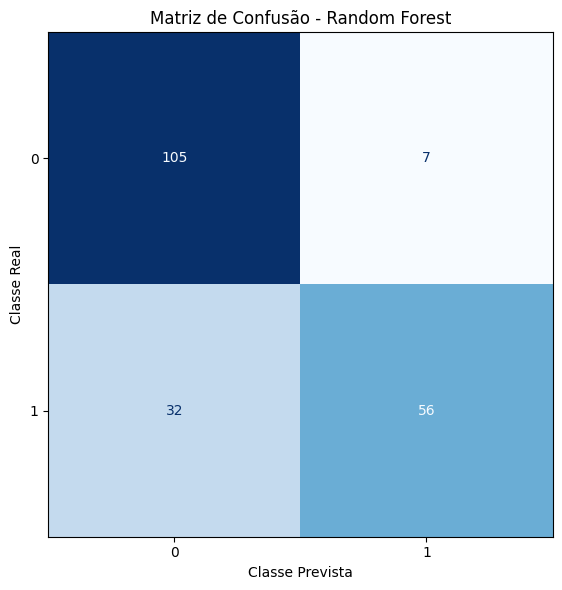

In [83]:
cm = confusion_matrix(Y_test, Y_pred2)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=best_model.classes_
)

fig, ax = plt.subplots(figsize=(8, 6))
disp.plot(cmap="Blues", values_format="d", ax=ax, colorbar=False)

plt.title("Matriz de Confusão - Random Forest")
plt.xlabel("Classe Prevista")
plt.ylabel("Classe Real")
plt.tight_layout()
plt.show()

**Resultados da Matriz de Confusão:**

- 105 exemplos 0 classificados corretamente.

- 7 exemplos 0 classificados incorretamente como 1.

- 32 exemplos 1 classificados incorretamente como 0.

- 56 exemplos 1 classificados corretamente.

O modelo apresentou grande dificuldade na classificação da classe 1.

### Curva ROC-AUC:

In [73]:
roc_auc = roc_auc_score(Y_test, Y_pred2)
print(f'AUC: \n{(roc_auc):.2f}')

AUC: 
0.79


In [74]:
fpr, tpr, thresholds = roc_curve(Y_test, Y_pred2)

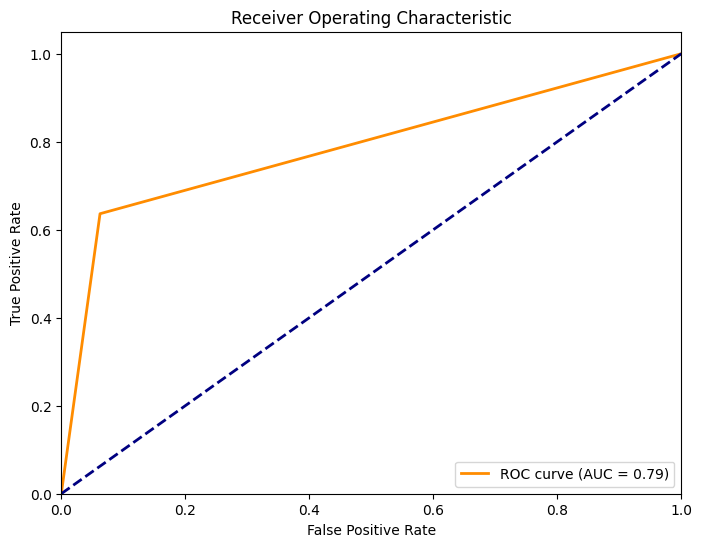

In [75]:
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

A curva `ROC` apresentou uma área sob a curva (`ROC-AUC`) de 0.79, indicando uma capacidade razoável de distinguir clientes que compraram o carro daqueles que não compraram.

**Considerações finais:**

De modo geral, o `SVC` com kernel `linear` apresentou desempenho consistente, com `accuracy` de 81% no teste, média de 83% na validação cruzada e `ROC-AUC` de 0.79. Entretanto, o `recall` de 64% para a classe 1 demonstra que o modelo ainda apresenta dificuldades para identificar todos os clientes que comprariam carro.

### Usando `permutation_importance` para avaliar a importância de cada variável para as previsões:

[LINK DA DOCUMENTAÇÃO](https://scikit-learn.org/stable/modules/permutation_importance.html)

O `permutation_importance` mede a importância de uma variável observando quanto o desempenho do modelo muda quando os valores dessa variável são embaralhados. **Quanto maior a queda no desempenho, maior tende a ser a importância daquela variável para a métrica escolhida.**

In [47]:
resultado = permutation_importance(
    best_model, X_test, Y_test,
    scoring='accuracy',
    n_repeats=10,
    random_state=42
)

In [48]:
importancias = pd.Series(resultado.importances_mean, index=X_test.columns).sort_values(ascending=False)
print(importancias)

Age_scaled             0.2260
AnnualSalary_scaled    0.0315
Gender_encoded        -0.0070
dtype: float64


As duas variáveis mais importantes coincidem nas duas análises: `Age_scaled` e `AnnualSalary_scaled`. Isso indica consistência entre a associação linear observada na **matriz de correlação** e a contribuição das variáveis para as previsões do **SVC** com kernel `linear`.

# 6. Treine um novo modelo SVM com sua base de treino + realize as previsões e avalições.

### **Modelo 2: kernel = 'poly'**

In [34]:
model2 = SVC(kernel='poly')

In [35]:
param_grid_poly = {
    "C": [0.1, 1, 10],
    "degree": [2, 3],
    "gamma": ["scale", "auto", 0.1],
    "coef0": [0, 1]
}

In [36]:
random_search2 = RandomizedSearchCV(
    model2,
    param_distributions=param_grid_poly,
    cv=cross_validation,
    n_iter=30,
    scoring='accuracy',
    n_jobs=-1,
    random_state=42
)

In [37]:
random_search2.fit(X_train, Y_train)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",SVC(kernel='poly')
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'C': [0.1, 1, ...], 'coef0': [0, 1], 'degree': [2, 3], 'gamma': ['scale', 'auto', ...]}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",30
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None 

In [38]:
best_param2 = random_search2.best_params_
print(f'Melhores Parâmetros: {best_param2}')

Melhores Parâmetros: {'gamma': 'scale', 'degree': 3, 'coef0': 1, 'C': 10}


In [39]:
best_model2 = random_search2.best_estimator_
best_model2.fit(X_train, Y_train)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",10
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'poly'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",1
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide `.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide `.",False
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


### Treino:

In [40]:
Y_pred3 = best_model2.predict(X_train)

report = classification_report(Y_train, Y_pred3)
print(f'Relatório de Classificação \n{report}')

Relatório de Classificação 
              precision    recall  f1-score   support

           0       0.93      0.91      0.92       486
           1       0.86      0.89      0.88       314

    accuracy                           0.90       800
   macro avg       0.90      0.90      0.90       800
weighted avg       0.90      0.90      0.90       800



O modelo `SVC` com kernel `poly` apresentou `accuracy` de 90% no conjunto de treinamento. Para a classe 0, obteve `precision` de 93% e `recall` de 91%, enquanto, para a classe 1, alcançou `precision` de 86% e `recall` de 89%. Esses resultados demonstram que o modelo conseguiu identificar adequadamente ambas as classes, apresentando um desempenho equilibrado na classificação dos clientes.

### Validação cruzada:

In [41]:
scores2 = cross_val_score(
    best_model2,
    X_train,
    Y_train,
    cv=cross_validation,
    scoring='accuracy',
    n_jobs=-1,
)

In [42]:
print(f'Scores cross validation: {scores2}')
print(f'Acurácia média: {np.mean(scores2):.2f}')
print(f'Desvio padrão: {np.std(scores2):.2f}')

Scores cross validation: [0.90625 0.91875 0.9     0.875   0.925  ]
Acurácia média: 0.91
Desvio padrão: 0.02


A **validação cruzada**, apresentou uma `accuracy` média de 91% e um desvio padrão (`std`) de 2 pontos percentuais. Os resultados demonstram que o modelo mantém um desempenho relativamente estável entre as diferentes partições dos dados.

### Teste:

In [43]:
Y_pred4 = best_model2.predict(X_test)

report = classification_report(Y_test, Y_pred4)
print(f'Relatório de Classificação \n{report}')

Relatório de Classificação 
              precision    recall  f1-score   support

           0       0.89      0.94      0.91       112
           1       0.91      0.85      0.88        88

    accuracy                           0.90       200
   macro avg       0.90      0.89      0.90       200
weighted avg       0.90      0.90      0.90       200



No conjunto de teste, o modelo manteve a `accuracy` de 90%, com `precision` de 89% e `recall` de 94% para a classe 0. Para a classe 1, obteve `precision` de 91% e `recall` de 85%, indicando uma boa capacidade de identificar os clientes que efetivamente compraram carro. A proximidade entre os resultados de treinamento e teste sugere uma boa capacidade de generalização, sem indícios de overfitting.

### Matriz de confusão:

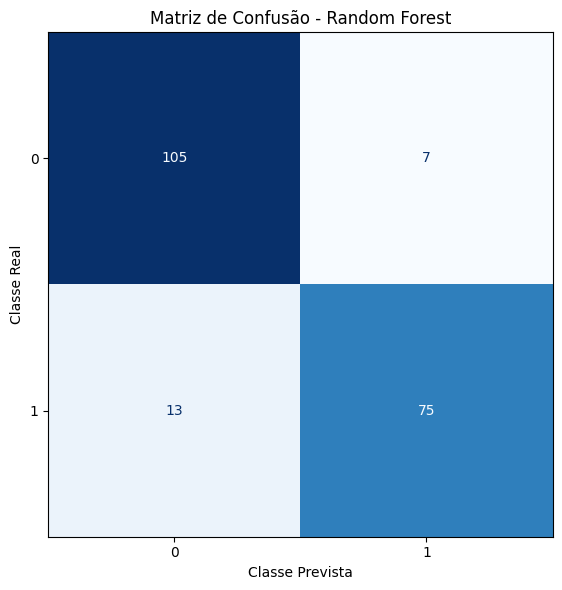

In [85]:
cm2 = confusion_matrix(Y_test, Y_pred4)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm2,
    display_labels=best_model2.classes_
)

fig, ax = plt.subplots(figsize=(8, 6))
disp.plot(cmap="Blues", values_format="d", ax=ax, colorbar=False)

plt.title("Matriz de Confusão - Random Forest")
plt.xlabel("Classe Prevista")
plt.ylabel("Classe Real")
plt.tight_layout()
plt.show()

**Resultados da Matriz de Confusão:**

- 105 exemplos 0 classificados corretamente.

- 7 exemplos 0 classificados incorretamente como 1.

- 13 exemplos 1 classificados incorretamente como 0.

- 75 exemplos 1 classificados corretamente.

O modelo apresentou maior dificuldade na classificação da classe 1.

### Curva ROC-AUC:

In [77]:
roc_auc2 = roc_auc_score(Y_test, Y_pred4)
print(f'AUC: \n{(roc_auc2):.2f}')

AUC: 
0.89


In [78]:
fpr, tpr, thresholds = roc_curve(Y_test, Y_pred4)

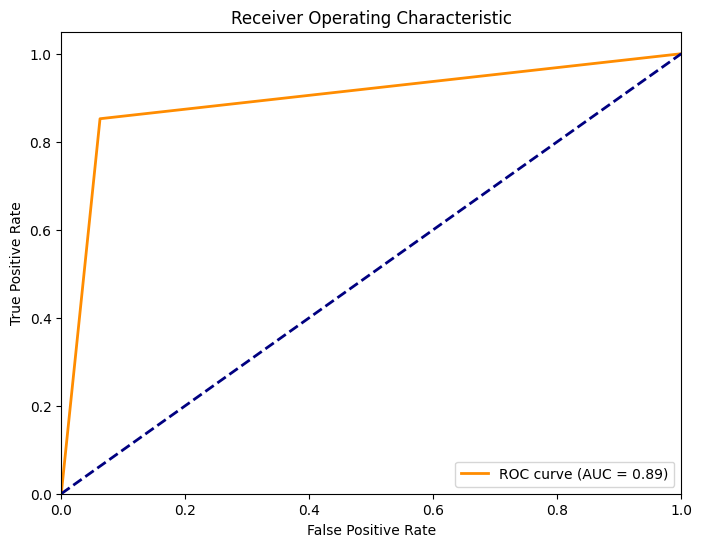

In [79]:
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc2:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

A curva `ROC` apresentou uma área sob a curva (`ROC-AUC`) de 0.89, indicando uma boa capacidade de distinguir clientes que compraram o carro daqueles que não compraram. Esse resultado demonstra uma capacidade discriminatória superior à observada no `SVC` com kernel `linear`, cuja `ROC-AUC` foi de 0.79.

**Considerações finais:**

De modo geral, o `SVC` com kernel `polinomial` apresentou resultados superiores aos obtidos com o kernel `linear`, alcançando 90% de `accuracy` no teste, aproximadamente 91% na validação cruzada e `ROC-AUC` de 0.89. Além disso, reduziu significativamente os falsos negativos, de 32 para 13, demonstrando maior capacidade de identificar clientes compradores.

### Usando `permutation_importance` para avaliar a importância de cada variável para as previsões:

In [49]:
resultado = permutation_importance(
    best_model2, X_test, Y_test,
    scoring='accuracy',
    n_repeats=10,
    random_state=42
)

In [53]:
importancias2 = pd.Series(resultado.importances_mean, index=X_test.columns).sort_values(ascending=False)
print(importancias2)

Age_scaled             0.2635
AnnualSalary_scaled    0.1620
Gender_encoded        -0.0060
dtype: float64


As duas variáveis mais importantes coincidem nas duas análises: `Age_scaled` e `AnnualSalary_scaled`. Isso indica consistência entre a associação linear observada na **matriz de correlação** e a contribuição das variáveis para as previsões do **SVC** com kernel `poly`.

### **kernel = 'rbf'**

In [54]:
model3 = SVC(kernel='rbf')

In [55]:
param_grid_rbf = {
    "C": [0.1, 1, 10],
    "degree": [2, 3],
    "gamma": ["scale", "auto", 0.1],
    "coef0": [0, 1]
}

In [56]:
random_search3 = RandomizedSearchCV(
    model3,
    param_distributions=param_grid_rbf,
    cv=cross_validation,
    n_iter=30,
    scoring='accuracy',
    n_jobs=-1,
    random_state=42
)

In [57]:
random_search3.fit(X_train, Y_train)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",SVC()
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'C': [0.1, 1, ...], 'coef0': [0, 1], 'degree': [2, 3], 'gamma': ['scale', 'auto', ...]}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",30
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 

In [58]:
best_param3 = random_search3.best_params_
print(f'Melhores Parâmetros: {best_param3}')

Melhores Parâmetros: {'gamma': 'scale', 'degree': 2, 'coef0': 1, 'C': 10}


In [59]:
best_model3 = random_search3.best_estimator_
best_model3.fit(X_train, Y_train)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",10
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",2
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",1
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide `.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide `.",False
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


### Treino:

In [60]:
Y_pred5 = best_model3.predict(X_train)

report = classification_report(Y_train, Y_pred5)
print(f'Relatório de Classificação \n{report}')

Relatório de Classificação 
              precision    recall  f1-score   support

           0       0.95      0.91      0.93       486
           1       0.87      0.92      0.89       314

    accuracy                           0.91       800
   macro avg       0.91      0.92      0.91       800
weighted avg       0.92      0.91      0.91       800



O modelo `SVC` com kernel `rbf` apresentou `accuracy` de 91% no conjunto de treinamento. Para a classe 0, obteve `precision` de 95% e `recall` de 91%, enquanto, para a classe 1, alcançou `precision` de 87% e `recall` de 92%. Esses resultados demonstram que o modelo conseguiu identificar adequadamente ambas as classes.

### Validação cruzada:

In [62]:
scores3 = cross_val_score(
    best_model3,
    X_train,
    Y_train,
    cv=cross_validation,
    scoring='accuracy',
    n_jobs=-1,
)

In [63]:
print(f'Scores cross validation: {scores3}')
print(f'Acurácia média: {np.mean(scores3):.2f}')
print(f'Desvio padrão: {np.std(scores3):.2f}')

Scores cross validation: [0.925   0.91875 0.90625 0.86875 0.90625]
Acurácia média: 0.91
Desvio padrão: 0.02


A **validação cruzada**, apresentou uma `accuracy` média de 91% e um desvio padrão (`std`) de 2 pontos percentuais. Os resultados demonstram que o modelo mantém um desempenho relativamente estável entre as diferentes partições dos dados.

### Teste:

In [64]:
Y_pred6 = best_model3.predict(X_test)

report = classification_report(Y_test, Y_pred6)
print(f'Relatório de Classificação \n{report}')

Relatório de Classificação 
              precision    recall  f1-score   support

           0       0.92      0.94      0.93       112
           1       0.92      0.90      0.91        88

    accuracy                           0.92       200
   macro avg       0.92      0.92      0.92       200
weighted avg       0.92      0.92      0.92       200



No conjunto de teste, o modelo alcançou `accuracy` de 92%, superando os 91% obtidos no treinamento. Para a classe 0, apresentou `precision` de 92% e `recall` de 94%. Já para a classe 1, obteve `precision` de 92% e `recall` de 90%, indicando uma boa capacidade de identificar os clientes que efetivamente compraram carro. A proximidade entre os resultados de treinamento e teste sugere uma boa capacidade de generalização, sem indícios de overfitting.

### Matriz de confusão:

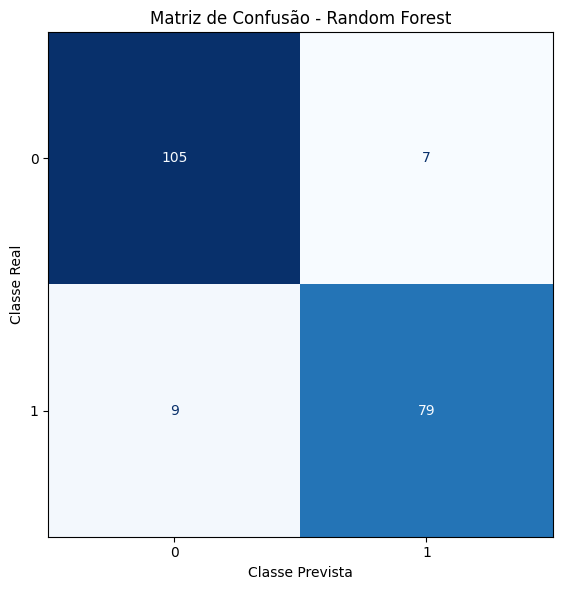

In [84]:
cm3 = confusion_matrix(Y_test, Y_pred6)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm3,
    display_labels=best_model3.classes_
)

fig, ax = plt.subplots(figsize=(8, 6))
disp.plot(cmap="Blues", values_format="d", ax=ax, colorbar=False)

plt.title("Matriz de Confusão - Random Forest")
plt.xlabel("Classe Prevista")
plt.ylabel("Classe Real")
plt.tight_layout()
plt.show()

**Resultados da Matriz de Confusão:**

- 105 exemplos 0 classificados corretamente.

- 7 exemplos 0 classificados incorretamente como 1.

- 9 exemplos 1 classificados incorretamente como 0.

- 79 exemplos 1 classificados corretamente.

O modelo apresentou maior dificuldade na classificação da classe 1.

### Curva ROC-AUC:

In [80]:
roc_auc3 = roc_auc_score(Y_test, Y_pred6)
print(f'AUC: \n{(roc_auc3):.2f}')

AUC: 
0.92


In [81]:
fpr, tpr, thresholds = roc_curve(Y_test, Y_pred6)

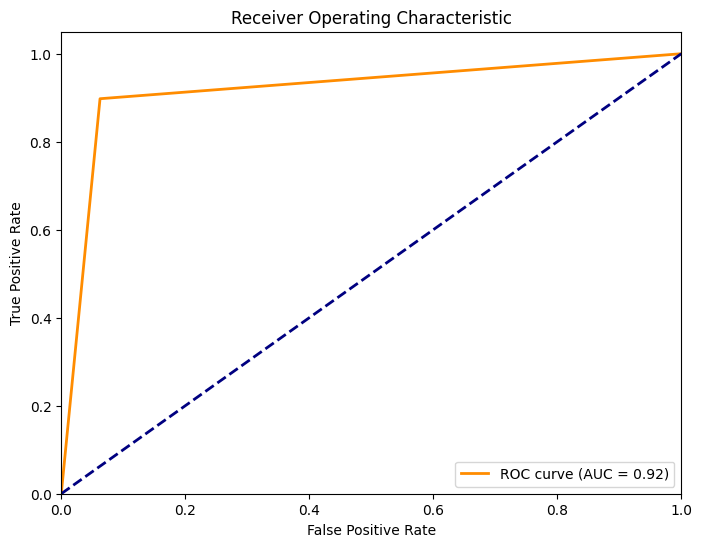

In [82]:
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc3:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

A curva `ROC` apresentou uma área sob a curva (`ROC-AUC`) de 0.92, indicando uma excelente capacidade de distinguir clientes que compraram o carro daqueles que não compraram.

Esse resultado supera os valores obtidos pelos kernels `linear` (0.79) e `polinomial` (0.89). Portanto, o `rbf` demonstrou a melhor capacidade discriminatória entre os três kernels avaliados.

**Considerações finais:**

O `SVC` com kernel `rbf` apresentou o melhor desempenho entre os três kernels testados, alcançando 92% de `accuracy` no conjunto de teste, aproximadamente 91% na validação cruzada e `ROC-AUC` de 0.92. Além disso, apresentou apenas 9 falsos negativos e 7 falsos positivos, demonstrando um bom equilíbrio na identificação das duas classes.

Comparado aos kernels `linear` e `polinomial`, o `rbf` apresentou resultados superiores no conjunto de teste e na capacidade de discriminação entre compradores e não compradores. Assim, o kernel `rbf` é a melhor opção para o problema de previsão de compra de carros.

### Usando `permutation_importance` para avaliar a importância de cada variável para as previsões:

In [65]:
resultado = permutation_importance(
    best_model3, X_test, Y_test,
    scoring='accuracy',
    n_repeats=10,
    random_state=42
)

In [66]:
importancias3 = pd.Series(resultado.importances_mean, index=X_test.columns).sort_values(ascending=False)
print(importancias3)

Age_scaled             0.268
AnnualSalary_scaled    0.193
Gender_encoded         0.004
dtype: float64


As duas variáveis mais importantes coincidem nas duas análises: `Age_scaled` e `AnnualSalary_scaled`. Isso indica consistência entre a associação linear observada na **matriz de correlação** e a contribuição das variáveis para as previsões do **SVC** com kernel `rbf`.

# 7. Qual modelo se saiu melhor? O SVM com kernel linear ou poly? Compare também com o XGboost, da atividade anterior, você obteve melhores previsões com qual dos modelos?

### Desempenho geral dos modelos:

| Métrica | SVC `linear` | SVC `poly` | SVC `rbg` | XGBoost |
|---|---:|---:|---:|---:|
| Acurácia no treinamento | 83% | 90% | 91% | **93%** |
| Acurácia média na validação cruzada | 83% | **91%** | **91%** | **91%** |
| Desvio-padrão da validação cruzada | 0,02 | 0,02 | 0,02 | 0,02 |
| Acurácia no teste | 81% | 90% | **92%** | **92%** |
| ROC-AUC | 0,79 | 0,89 | **0,92** | 0,91 |

### Métricas de classificação no conjunto de teste:

| Métrica | SVC `linear` | SVC `poly` | SVC `rbf` | XGBoost |
|---|---:|---:|---:|---:|
| Precisão — Classe 0 | 0,77 | 0,89 | **0,92** | 0,91 |
| Recall — Classe 0 | 0,94 | 0,94 | 0,94 | **0,95** |
| F1-score — Classe 0 | 0,84 | 0,91 | **0,93** | **0,93** |
| Precisão — Classe 1 | 0,89 | 0,91 | 0,92 | **0,93** |
| Recall — Classe 1 | 0,64 | 0,85 | **0,90** | 0,88 |
| F1-score — Classe 1 | 0,74 | 0,88 | **0,91** | 0,90 |

### Matriz de confusão no conjunto de teste:

| Resultado | SVC `linear` | SVC `poly` | SVC `rbf` | XGBoost |
|---|---:|---:|---:|---:|
| Verdadeiros negativos (TN) | 105 | 105 | 105 | 106 |
| Falsos positivos (FP) | 7 | 7 | 7 | 6 |
| Falsos negativos (FN) | 32 | 13 | **9** | 11 |
| Verdadeiros positivos (TP) | 56 | 75 | **79** | 77 |
| Total de acertos | 161 | 180 | **184** | 183 |
| Total de erros | 39 | 20 | **16** | 17 |

### Conclusão Final:

Considerando os resultados obtidos, o `SVC` com kernel `rbf` foi o modelo que apresentou as melhores previsões no conjunto de teste, embora o `XGBoost` tenha alcançado a mesma `accuracy`. O `rbf` demonstrou melhor capacidade de discriminação, segundo a `ROC-AUC`, e identificou uma quantidade maior de compradores. Já o `XGBoost` apresentou menos falsos positivos e maior precisão para a classe 1. Assim, os dois modelos tiveram desempenhos bastante próximos, com pequenas vantagens para cada um em métricas diferentes.

Portanto, como o objetivo principal é identificar o maior número possível de clientes que comprarão o carro, o `SVC` com kernel `rbf` é a melhor opção entre os modelos avaliados.